# GARCH Volatility Modeling
## Eli Lilly (LLY) : Conditional Volatility & Forecasting

This notebook implements a **GARCH(1,1)** model on Eli Lilly's real historical returns.

Unlike Black-Scholes which assumes **constant volatility**, GARCH models volatility as **time-varying**, capturing the well-known phenomenon of **volatility clustering**: turbulent periods tend to be followed by turbulent periods, and calm periods by calm periods.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model

# Download real data for Eli Lilly
data = yf.download("LLY", period="2y")["Close"]
returns = data.pct_change().dropna() * 100

print(f"Data downloaded: {len(returns)} daily returns")
print(f"Average daily return: {round(float(returns.mean().iloc[0]), 4)}%")
print(f"Average daily volatility: {round(float(returns.std().iloc[0]), 4)}%")

[*********************100%***********************]  1 of 1 completed

Data downloaded: 500 daily returns
Average daily return: 0.082%
Average daily volatility: 2.3906%


## Volatility Clustering
Before fitting the GARCH model, let's visualize the daily returns to observe the **volatility clustering** phenomenon.

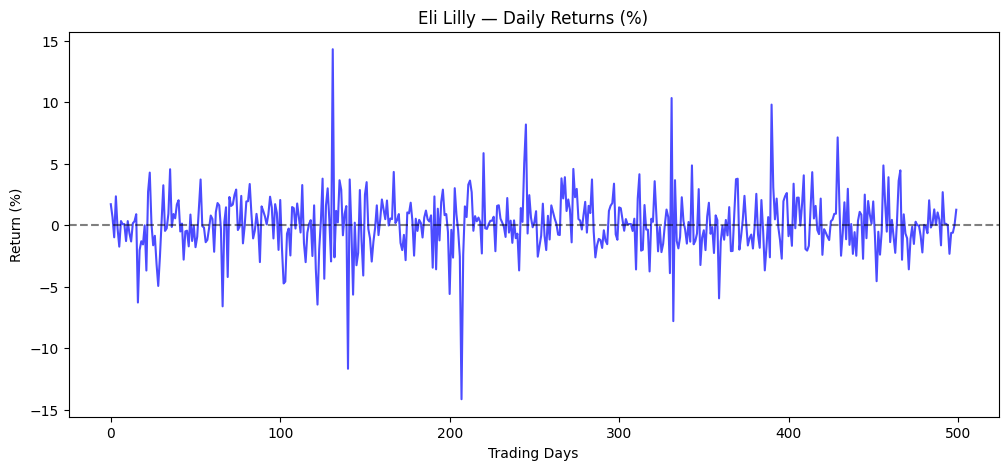

In [2]:
plt.figure(figsize=(12, 5))
plt.plot(returns.values, color="blue", alpha=0.7)
plt.axhline(y=0, color="black", linestyle="--", alpha=0.5)
plt.title("Eli Lilly — Daily Returns (%)")
plt.xlabel("Trading Days")
plt.ylabel("Return (%)")
plt.show()

## The GARCH(1,1) Formula

The GARCH(1,1) model estimates today's variance as :

$$\sigma^2_t = \omega + \alpha \cdot \varepsilon^2_{t-1} + \beta \cdot \sigma^2_{t-1}$$

Where :
- $\sigma^2_t$ : today's conditional variance
- $\omega$ : constant base level of volatility
- $\alpha$ : impact of yesterday's shock $\varepsilon^2_{t-1}$ on today's volatility
- $\beta$ : persistence of yesterday's volatility $\sigma^2_{t-1}$ into today
- $\alpha + \beta < 1$ : ensures the model is stationary (volatility always mean-reverts)

## GARCH(1,1) Model

In [5]:
# Fit GARCH(1,1) model
model = arch_model(returns, vol="Garch", p=1, q=1)
result = model.fit(disp="off")

print(result.summary())

# Long run volatility
omega = result.params["omega"]
alpha = result.params["alpha[1]"]
beta = result.params["beta[1]"]

long_run_vol = np.sqrt(omega / (1 - alpha - beta))
print(f"\nLong run daily volatility: {round(long_run_vol, 4)}%")
print(f"Long run annual volatility: {round(long_run_vol * np.sqrt(252), 4)}%")
print(f"Alpha + Beta (persistence): {round(alpha + beta, 4)}")


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    LLY   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1138.17
Distribution:                  Normal   AIC:                           2284.35
Method:            Maximum Likelihood   BIC:                           2301.21
                                        No. Observations:                  500
Date:                Wed, Oct 07 2026   Df Residuals:                      499
Time:                        11:18:14   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.1200      0.113      1.066      0.286 [ -0.101,  0.34

## Conditional Volatility
The GARCH model estimates a **different volatility for each day**, unlike Black-Scholes which uses a single constant sigma. The graph below shows how Eli Lilly's volatility evolved over the past 2 years.

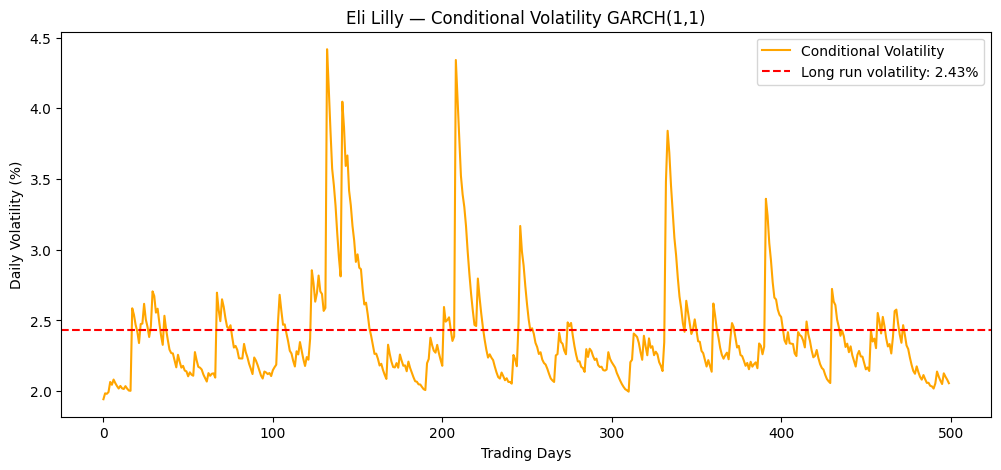

In [ ]:
conditional_vol = result.conditional_volatility

plt.figure(figsize=(12, 5))
plt.plot(conditional_vol.values, color="orange", label="Conditional Volatility")
plt.axhline(y=float(long_run_vol), color="red", linestyle="--", label=f"Long run volatility: {round(float(long_run_vol), 2)}%")
plt.title("Eli Lilly : Conditional Volatility GARCH(1,1)")
plt.xlabel("Trading Days")
plt.ylabel("Daily Volatility (%)")
plt.legend()
plt.show()

## Volatility Forecast : Next 10 Days

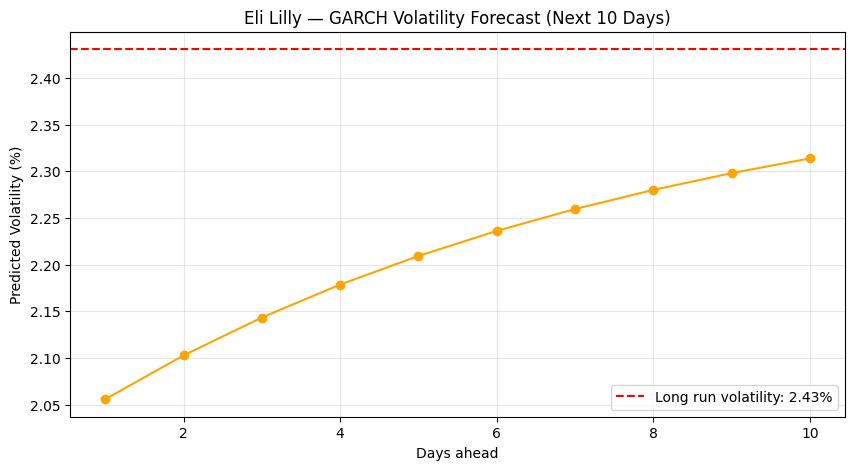

Volatility Forecast — Next 10 Days:
----------------------------------------
Day 1: 2.0558%
Day 2: 2.1027%
Day 3: 2.1432%
Day 4: 2.1785%
Day 5: 2.2092%
Day 6: 2.236%
Day 7: 2.2594%
Day 8: 2.2799%
Day 9: 2.2979%
Day 10: 2.3137%


In [7]:
# Forecast next 10 days
forecast = result.forecast(horizon=10)
forecast_vol = np.sqrt(forecast.variance.dropna().iloc[-1])

# Plot forecast
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), forecast_vol.values, color="orange", marker="o")
plt.axhline(y=float(long_run_vol), color="red", linestyle="--",
            label=f"Long run volatility: {round(float(long_run_vol), 2)}%")
plt.title("Eli Lilly — GARCH Volatility Forecast (Next 10 Days)")
plt.xlabel("Days ahead")
plt.ylabel("Predicted Volatility (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Volatility Forecast — Next 10 Days:")
print("-" * 40)
for i, vol in enumerate(forecast_vol.values):
    print(f"Day {i+1}: {round(vol, 4)}%")

## Understanding the Forecast Direction

Looking at the graph, the forecast curve is **increasing** and **below** the long run volatility line (2.43%).

This means Eli Lilly is currently in a **calm period**, the most recent days had lower volatility than the historical average. The GARCH model predicts volatility will **gradually rise** back toward its long run equilibrium.

Notice the shape of the curve, it rises **steeply at first** then **flattens** as it approaches the long run level. This is mean reversion losing strength as volatility gets closer to equilibrium, like a spring that pulls harder when stretched far, and less hard when nearly back to its natural length.

This works in both directions :
- Current volatility **below** long run → forecast **increases** toward it
- Current volatility **above** long run → forecast **decreases** toward it

The speed of this return is controlled by **Alpha + Beta = 0.88**, close to 1 means slow mean reversion, which explains why the curve hasn't reached 2.43% even after 10 days.

## Key Findings & Conclusions

### GARCH(1,1) Parameters — Eli Lilly
| Parameter | Value | Interpretation |
|-----------|-------|----------------|
| Omega | 0.6848 | Base level of volatility |
| Alpha | 0.0665 | Impact of past shocks on volatility |
| Beta | 0.8176 | Persistence of volatility over time |
| Alpha + Beta | 0.8841 | Speed of mean reversion (close to 1 = slow) |
| Long run volatility | 2.43% daily / 38.6% annual | Equilibrium volatility level |

### Key Findings
1. **Volatility clustering is real** : calm periods and turbulent periods cluster together, confirming the GARCH assumption.
2. **Volatility is highly persistent** : Beta of 0.82 means yesterday's volatility strongly predicts today's.
3. **Mean reversion always occurs** : Alpha + Beta < 1 guarantees volatility always returns to its long run level.
4. **Current calm period** : today's volatility is below the long run average, forecast predicts a gradual increase.

### Statistical Significance — A Critical Look
Not all parameters are equally significant :
- **Omega** (p = 0.027)  — statistically significant
- **Alpha** (p = 0.197)  — not significant at 95% confidence
- **Beta** (p ≈ 0.000) — extremely significant

The low significance of alpha suggests that **individual shocks** have a limited measurable impact on Eli Lilly's volatility. However **beta's overwhelming significance** confirms that **volatility persistence** is the dominant force.

GARCH(1,1) remains the industry standard despite this limitation — in practice, models are rarely perfect, and a model that captures the main dynamics (persistence via beta) is still valuable even when secondary effects (alpha) are harder to measure precisely.

### Black-Scholes Limitation
Black-Scholes prices options using a **single constant sigma**. But as this notebook demonstrates, Eli Lilly's volatility changes every single day, meaning options are systematically mispriced using a constant sigma.

GARCH provides a more realistic, time-varying volatility estimate. This is the foundation of **stochastic volatility models** like **Heston**, which extends Black-Scholes by letting sigma follow its own random process, our next project.